## Problem 10: Predicting CO₂ Emissions Intensity Using Economic and Energy Indicators

**Importing Libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import TimeSeriesSplit

In [2]:
owid_url = "https://raw.githubusercontent.com/owid/co2-data/master/owid-co2-data.csv"

data = pd.read_csv(owid_url)

data.head()

,country,year,iso_code,population,gdp,cement_co2,cement_co2_per_capita,co2,co2_growth_abs,co2_growth_prct,...,share_global_other_co2,share_of_temperature_change_from_ghg,temperature_change_from_ch4,temperature_change_from_co2,temperature_change_from_ghg,temperature_change_from_n2o,total_ghg,total_ghg_excluding_lucf,trade_co2,trade_co2_share
0,Afghanistan,1750,AFG,2802560.0,NaN,0.0,0.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Afghanistan,1751,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,1752,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,1753,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,1754,AFG,NaN,NaN,0.0,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
data.shape

(50411, 79)

In [4]:
data.columns.tolist()

['country',
 'year',
 'iso_code',
 'population',
 'gdp',
 'cement_co2',
 'cement_co2_per_capita',
 'co2',
 'co2_growth_abs',
 'co2_growth_prct',
 'co2_including_luc',
 'co2_including_luc_growth_abs',
 'co2_including_luc_growth_prct',
 'co2_including_luc_per_capita',
 'co2_including_luc_per_gdp',
 'co2_including_luc_per_unit_energy',
 'co2_per_capita',
 'co2_per_gdp',
 'co2_per_unit_energy',
 'coal_co2',
 'coal_co2_per_capita',
 'consumption_co2',
 'consumption_co2_per_capita',
 'consumption_co2_per_gdp',
 'cumulative_cement_co2',
 'cumulative_co2',
 'cumulative_co2_including_luc',
 'cumulative_coal_co2',
 'cumulative_flaring_co2',
 'cumulative_gas_co2',
 'cumulative_luc_co2',
 'cumulative_oil_co2',
 'cumulative_other_co2',
 'energy_per_capita',
 'energy_per_gdp',
 'flaring_co2',
 'flaring_co2_per_capita',
 'gas_co2',
 'gas_co2_per_capita',
 'ghg_excluding_lucf_per_capita',
 'ghg_per_capita',
 'land_use_change_co2',
 'land_use_change_co2_per_capita',
 'methane',
 'methane_per_capita',
 

In [5]:
co2 = data.copy()

co2 = co2[
    co2["iso_code"].notna()
].copy()

co2 = co2[
    co2["iso_code"].astype(str).str.len() == 3
].copy()

co2[["country", "iso_code", "year"]].head()

,country,iso_code,year
0,Afghanistan,AFG,1750
1,Afghanistan,AFG,1751
2,Afghanistan,AFG,1752
3,Afghanistan,AFG,1753
4,Afghanistan,AFG,1754


In [6]:
selected_columns = [
    "country",
    "iso_code",
    "year",
    "co2_per_gdp",
    "co2_per_capita",
    "gdp",
    "population",
    "primary_energy_consumption",
    "energy_per_capita",
    "energy_per_gdp",
    "co2_per_unit_energy",
    "coal_co2_per_capita",
    "oil_co2_per_capita",
    "gas_co2_per_capita",
    "cement_co2_per_capita",
    "trade_co2"
]

available_columns = [
    col for col in selected_columns
    if col in co2.columns
]

co2_model = co2[available_columns].copy()

co2_model.head()

,country,iso_code,year,co2_per_gdp,co2_per_capita,gdp,population,primary_energy_consumption,energy_per_capita,energy_per_gdp,co2_per_unit_energy,coal_co2_per_capita,oil_co2_per_capita,gas_co2_per_capita,cement_co2_per_capita,trade_co2
0,Afghanistan,AFG,1750,NaN,NaN,NaN,2802560.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN
1,Afghanistan,AFG,1751,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,AFG,1752,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,AFG,1753,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,AFG,1754,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
co2_model = co2_model.rename(columns={
    "country": "Country",
    "iso_code": "ISO_Code",
    "year": "Year",
    "co2_per_gdp": "CO2_per_GDP",
    "co2_per_capita": "CO2_per_Capita",
    "gdp": "GDP",
    "population": "Population",
    "primary_energy_consumption": "Primary_Energy_Consumption",
    "energy_per_capita": "Energy_per_Capita",
    "energy_per_gdp": "Energy_per_GDP",
    "co2_per_unit_energy": "CO2_per_Unit_Energy",
    "coal_co2_per_capita": "Coal_CO2_per_Capita",
    "oil_co2_per_capita": "Oil_CO2_per_Capita",
    "gas_co2_per_capita": "Gas_CO2_per_Capita",
    "cement_co2_per_capita": "Cement_CO2_per_Capita",
    "trade_co2": "Trade_CO2"
})

co2_model.head()

,Country,ISO_Code,Year,CO2_per_GDP,CO2_per_Capita,GDP,Population,Primary_Energy_Consumption,Energy_per_Capita,Energy_per_GDP,CO2_per_Unit_Energy,Coal_CO2_per_Capita,Oil_CO2_per_Capita,Gas_CO2_per_Capita,Cement_CO2_per_Capita,Trade_CO2
0,Afghanistan,AFG,1750,NaN,NaN,NaN,2802560.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN
1,Afghanistan,AFG,1751,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,AFG,1752,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Afghanistan,AFG,1753,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Afghanistan,AFG,1754,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
co2_model = co2_model.sort_values(["ISO_Code", "Year"])

co2_model["Next_Year_CO2_per_GDP"] = (
    co2_model.groupby("ISO_Code")["CO2_per_GDP"].shift(-1)
)

co2_model[
    [
        "Country",
        "ISO_Code",
        "Year",
        "CO2_per_GDP",
        "Next_Year_CO2_per_GDP"
    ]
].head(10)

,Country,ISO_Code,Year,CO2_per_GDP,Next_Year_CO2_per_GDP
2504,Aruba,ABW,1850,NaN,NaN
2505,Aruba,ABW,1851,NaN,NaN
2506,Aruba,ABW,1852,NaN,NaN
2507,Aruba,ABW,1853,NaN,NaN
2508,Aruba,ABW,1854,NaN,NaN
2509,Aruba,ABW,1855,NaN,NaN
2510,Aruba,ABW,1856,NaN,NaN
2511,Aruba,ABW,1857,NaN,NaN
2512,Aruba,ABW,1858,NaN,NaN
2513,Aruba,ABW,1859,NaN,NaN


In [9]:
log_columns = [
    "GDP",
    "Population",
    "Primary_Energy_Consumption",
    "Energy_per_Capita"
]

for col in log_columns:
    if col in co2_model.columns:
        co2_model["Log_" + col] = np.log(co2_model[col].where(co2_model[col] > 0))

co2_model.head()

,Country,ISO_Code,Year,CO2_per_GDP,CO2_per_Capita,GDP,Population,Primary_Energy_Consumption,Energy_per_Capita,Energy_per_GDP,...,Coal_CO2_per_Capita,Oil_CO2_per_Capita,Gas_CO2_per_Capita,Cement_CO2_per_Capita,Trade_CO2,Next_Year_CO2_per_GDP,Log_GDP,Log_Population,Log_Primary_Energy_Consumption,Log_Energy_per_Capita
2504,Aruba,ABW,1850,NaN,NaN,NaN,2720.0,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7.908387,NaN,NaN
2505,Aruba,ABW,1851,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2506,Aruba,ABW,1852,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2507,Aruba,ABW,1853,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2508,Aruba,ABW,1854,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
co2_model = co2_model[
    co2_model["Year"] >= 1990
].copy()

co2_model["Year"].min(), co2_model["Year"].max()

(np.int64(1990), np.int64(2024))

**Create country fixed-effect dummies**

This is the hard part. Countries differ permanently in geography, industrial structure, energy systems and income levels. Country dummies help control for those persistent differences.

In [11]:
country_dummies = pd.get_dummies(
    co2_model["ISO_Code"],
    prefix="Country",
    drop_first=True,
    dtype=int
)

country_dummies.head()

,Country_AFG,Country_AGO,Country_AIA,Country_ALB,Country_AND,Country_ARE,Country_ARG,Country_ARM,Country_ATA,Country_ATG,...,Country_VEN,Country_VGB,Country_VNM,Country_VUT,Country_WLF,Country_WSM,Country_YEM,Country_ZAF,Country_ZMB,Country_ZWE
2644,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2645,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2646,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2647,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2648,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [12]:
numeric_features = [
    "CO2_per_Capita",
    "Energy_per_GDP",
    "CO2_per_Unit_Energy",
    "Coal_CO2_per_Capita",
    "Oil_CO2_per_Capita",
    "Gas_CO2_per_Capita",
    "Cement_CO2_per_Capita",
    "Trade_CO2",
    "Log_GDP",
    "Log_Population",
    "Log_Primary_Energy_Consumption",
    "Log_Energy_per_Capita"
]

numeric_features = [
    col for col in numeric_features
    if col in co2_model.columns
]

numeric_features

['CO2_per_Capita',
 'Energy_per_GDP',
 'CO2_per_Unit_Energy',
 'Coal_CO2_per_Capita',
 'Oil_CO2_per_Capita',
 'Gas_CO2_per_Capita',
 'Cement_CO2_per_Capita',
 'Trade_CO2',
 'Log_GDP',
 'Log_Population',
 'Log_Primary_Energy_Consumption',
 'Log_Energy_per_Capita']

In [13]:
model_data = pd.concat(
    [
        co2_model[
            [
                "Country",
                "ISO_Code",
                "Year",
                "Next_Year_CO2_per_GDP"
            ] + numeric_features
        ],
        country_dummies
    ],
    axis=1
)

model_data = model_data.dropna(
    subset=[
        "Next_Year_CO2_per_GDP"
    ]
)

model_data.shape

(5246, 233)

In [14]:
country_dummy_features = country_dummies.columns.tolist()

features = numeric_features + country_dummy_features

len(features)

229

In [15]:
train = model_data[model_data["Year"] < 2015].copy()
test = model_data[model_data["Year"] >= 2015].copy()

train.shape, test.shape

((4098, 233), (1148, 233))

In [16]:
X_train = train[features]
y_train = train["Next_Year_CO2_per_GDP"]

X_test = test[features]
y_test = test["Next_Year_CO2_per_GDP"]

X_train.shape, X_test.shape

((4098, 229), (1148, 229))

In [17]:
ols_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("linear", LinearRegression())
])

ols_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](229,)","['CO2_per_Capita','Energy_per_GDP','CO2_per_Unit_Energy',...,'Country_ZAF', 'Country_ZMB','Country_ZWE']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,229
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value

**Robustness Check**

Ridge Regression with Expanded Alpha Grid

In the initial Ridge model, the selected alpha was at the upper boundary of the search grid. This suggested that the model may have required stronger regularisation than the original grid allowed. I therefore expanded the alpha range and refitted the Ridge model. The selected alpha after this robustness check was 14166.4327, confirming that strong regularisation is appropriate for this problem.

In [28]:
alpha_values = np.logspace(-4, 6, 120)

time_split = TimeSeriesSplit(n_splits=5)

ridge_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("ridge", RidgeCV(alphas=alpha_values, cv=time_split))
])

ridge_model.fit(X_train, y_train)

best_alpha = ridge_model.named_steps["ridge"].alpha_

best_alpha

np.float64(14166.43274669025)

In [29]:
ols_predictions = ols_model.predict(X_test)

ridge_predictions = ridge_model.predict(X_test)

In [30]:
ols_rmse = np.sqrt(mean_squared_error(y_test, ols_predictions))
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_predictions))

ols_mae = mean_absolute_error(y_test, ols_predictions)
ridge_mae = mean_absolute_error(y_test, ridge_predictions)

ols_r2 = r2_score(y_test, ols_predictions)
ridge_r2 = r2_score(y_test, ridge_predictions)

performance_comparison = pd.DataFrame({
    "Model": ["OLS Linear Regression", "Ridge Regression"],
    "RMSE": [ols_rmse, ridge_rmse],
    "MAE": [ols_mae, ridge_mae],
    "Test R-squared": [ols_r2, ridge_r2]
})

performance_comparison

,Model,RMSE,MAE,Test R-squared
0,OLS Linear Regression,0.334535,0.157374,-2.421663
1,Ridge Regression,0.165657,0.134009,0.160980


In [31]:
benchmark_prediction = y_train.mean()

benchmark_predictions = np.repeat(
    benchmark_prediction,
    len(y_test)
)

benchmark_rmse = np.sqrt(mean_squared_error(y_test, benchmark_predictions))
benchmark_mae = mean_absolute_error(y_test, benchmark_predictions)
benchmark_r2 = r2_score(y_test, benchmark_predictions)

benchmark_comparison = pd.DataFrame({
    "Model": [
        "Mean Benchmark",
        "OLS Linear Regression",
        "Ridge Regression"
    ],
    "RMSE": [
        benchmark_rmse,
        ols_rmse,
        ridge_rmse
    ],
    "MAE": [
        benchmark_mae,
        ols_mae,
        ridge_mae
    ],
    "Test R-squared": [
        benchmark_r2,
        ols_r2,
        ridge_r2
    ]
})

benchmark_comparison

,Model,RMSE,MAE,Test R-squared
0,Mean Benchmark,0.218080,0.183476,-0.454078
1,OLS Linear Regression,0.334535,0.157374,-2.421663
2,Ridge Regression,0.165657,0.134009,0.160980


In [32]:
ols_coefficients = ols_model.named_steps["linear"].coef_
ridge_coefficients = ridge_model.named_steps["ridge"].coef_

coefficient_comparison = pd.DataFrame({
    "Feature": features,
    "OLS Coefficient": ols_coefficients,
    "Ridge Coefficient": ridge_coefficients
})

coefficient_comparison["Abs OLS Coefficient"] = coefficient_comparison["OLS Coefficient"].abs()
coefficient_comparison["Abs Ridge Coefficient"] = coefficient_comparison["Ridge Coefficient"].abs()

numeric_coefficient_comparison = coefficient_comparison[
    coefficient_comparison["Feature"].isin(numeric_features)
].copy()

numeric_coefficient_comparison.sort_values(
    by="Abs OLS Coefficient",
    ascending=False
)

,Feature,OLS Coefficient,Ridge Coefficient,Abs OLS Coefficient,Abs Ridge Coefficient
9,Log_Population,0.883628,-0.005512,0.883628,0.005512
8,Log_GDP,-0.863563,-0.005042,0.863563,0.005042
4,Oil_CO2_per_Capita,-0.321645,0.005176,0.321645,0.005176
1,Energy_per_GDP,0.236055,0.058126,0.236055,0.058126
11,Log_Energy_per_Capita,0.196898,0.019731,0.196898,0.019731
0,CO2_per_Capita,0.150910,0.018337,0.150910,0.018337
2,CO2_per_Unit_Energy,0.143294,0.009044,0.143294,0.009044
5,Gas_CO2_per_Capita,-0.114081,0.023301,0.114081,0.023301
10,Log_Primary_Energy_Consumption,-0.042440,0.010975,0.042440,0.010975
6,Cement_CO2_per_Capita,-0.020164,0.005323,0.020164,0.005323


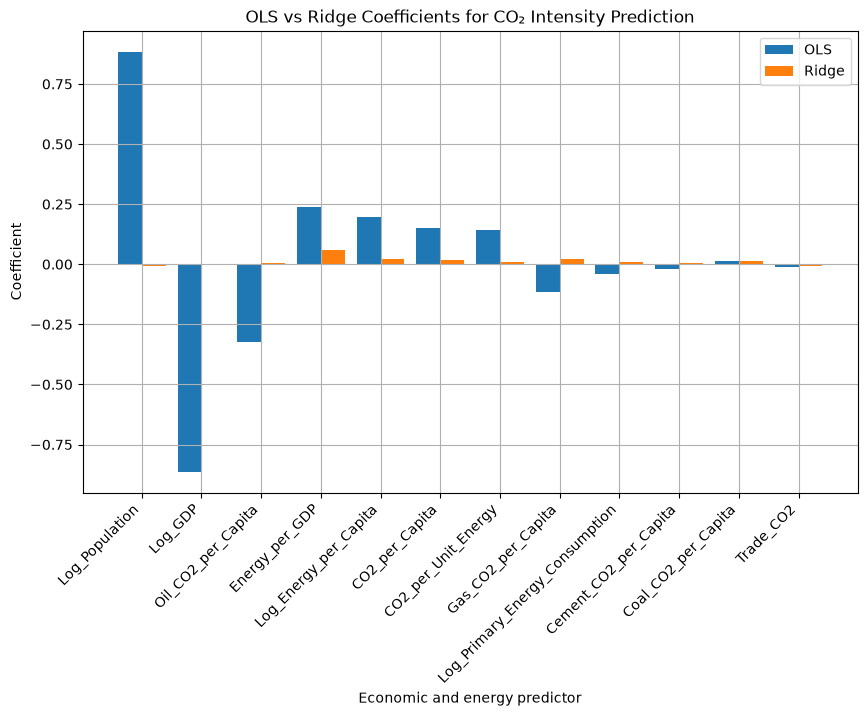

In [33]:
plot_coefficients = numeric_coefficient_comparison.sort_values(
    by="Abs OLS Coefficient",
    ascending=False
)

plt.figure(figsize=(10, 6))

x = np.arange(len(plot_coefficients))

plt.bar(
    x - 0.2,
    plot_coefficients["OLS Coefficient"],
    width=0.4,
    label="OLS"
)

plt.bar(
    x + 0.2,
    plot_coefficients["Ridge Coefficient"],
    width=0.4,
    label="Ridge"
)

plt.xticks(x, plot_coefficients["Feature"], rotation=45, ha="right")

plt.xlabel("Economic and energy predictor")
plt.ylabel("Coefficient")
plt.title("OLS vs Ridge Coefficients for CO₂ Intensity Prediction")
plt.legend()
plt.grid(True)

plt.show()

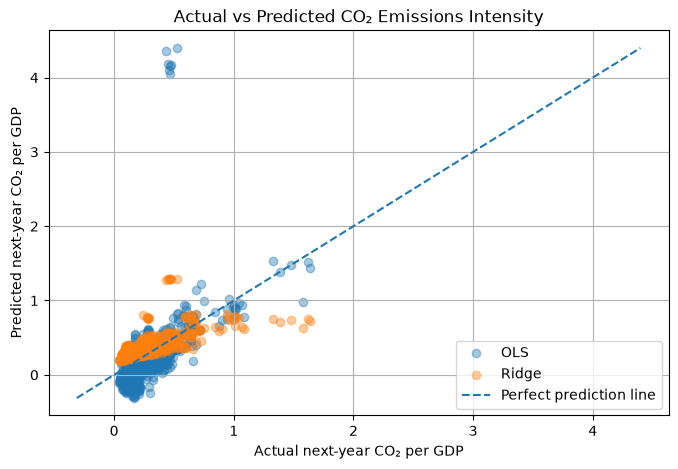

In [35]:
prediction_plot = test[
    [
        "Country",
        "ISO_Code",
        "Year",
        "Next_Year_CO2_per_GDP"
    ]
].copy()

prediction_plot["OLS_Prediction"] = ols_predictions
prediction_plot["Ridge_Prediction"] = ridge_predictions

plt.figure(figsize=(8, 5))

plt.scatter(
    prediction_plot["Next_Year_CO2_per_GDP"],
    prediction_plot["OLS_Prediction"],
    alpha=0.4,
    label="OLS"
)

plt.scatter(
    prediction_plot["Next_Year_CO2_per_GDP"],
    prediction_plot["Ridge_Prediction"],
    alpha=0.4,
    label="Ridge"
)

min_value = min(
    prediction_plot["Next_Year_CO2_per_GDP"].min(),
    prediction_plot["OLS_Prediction"].min(),
    prediction_plot["Ridge_Prediction"].min()
)

max_value = max(
    prediction_plot["Next_Year_CO2_per_GDP"].max(),
    prediction_plot["OLS_Prediction"].max(),
    prediction_plot["Ridge_Prediction"].max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    label="Perfect prediction line"
)

plt.xlabel("Actual next-year CO₂ per GDP")
plt.ylabel("Predicted next-year CO₂ per GDP")
plt.title("Actual vs Predicted CO₂ Emissions Intensity")
plt.legend()
plt.grid(True)

plt.show()

In [36]:
prediction_plot["OLS_Residual"] = (
    prediction_plot["Next_Year_CO2_per_GDP"] 
    - prediction_plot["OLS_Prediction"]
)

prediction_plot["Ridge_Residual"] = (
    prediction_plot["Next_Year_CO2_per_GDP"] 
    - prediction_plot["Ridge_Prediction"]
)

residual_comparison = pd.DataFrame({
    "Model": ["OLS Linear Regression", "Ridge Regression"],
    "Residual Mean": [
        prediction_plot["OLS_Residual"].mean(),
        prediction_plot["Ridge_Residual"].mean()
    ],
    "Residual Standard Deviation": [
        prediction_plot["OLS_Residual"].std(),
        prediction_plot["Ridge_Residual"].std()
    ]
})

residual_comparison

,Model,Residual Mean,Residual Standard Deviation
0,OLS Linear Regression,0.075524,0.326040
1,Ridge Regression,-0.106222,0.127173


## END